# 02 — Baseline, contact point and Hertz-like fit

**What this notebook does**

- reads the `segment0` (extend/approach) curves exported by notebook 01 (`afm_output/manifests/segment0_manifest.csv`);
- estimates the robust linear baseline, the noise and the *contact point* of every curve;
- builds the indentation $\delta = z_c - z$ and fits the Hertz-like model $F(\delta) = A\,\delta^{3/2}$ with $A$ and $z_c$ free;
- assigns a fit quality flag (`good` / `suspicious` / `bad`), informative only;
- repeats the fit with 9 preprocessing variants (baseline, threshold, fit window) for the systematic study (notebook 03);
- extracts adhesion features from the retract (`segment1`), used by notebook 05;
- saves the **light** tables in `results/` (tracked by git), so that notebooks 03–05 run without the raw data.

**What it does NOT do**

- it does not discard any curve: exclusion happens downstream, explicitly, in notebooks 03–05;
- it does not convert $A$ into a Young modulus: tip radius and Poisson ratio are needed (`tip_radius` is empty in the JPK metadata), so $A$ stays an *effective* elastic parameter in nN/µm$^{3/2}$, comparable only among groups measured with the same cantilever;
- it applies no corrections for sample thickness, adhesion or viscoelasticity.

**Convention.** In `segment0` the vertical position `z_tip_um` *decreases* along the curve: the baseline (tip far away) is at the start of the array, the contact towards the end. The prototype `Preliminary/02_..._v4` estimated the baseline on the last 20% of the curve (i.e. inside the contact region): this is fixed here.

Group names are kept as in the data folders: `cito` = cytoplasm, `nucleo` = nucleus.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import afm_tools as T

T.set_plot_style()
T.RESULTS_DIR.mkdir(exist_ok=True)
PLOTS_DIR = T.OUTPUT_DIR / "fit_plots"; PLOTS_DIR.mkdir(exist_ok=True)

manifest = T.load_manifest()
print(len(manifest), "segment0 curves")
print(manifest.groupby("group").size())

257 segment0 curves
group
Petri20k_MCF7R_t48h_cito_20260225      55
Petri20k_MCF7R_t48h_nucleo_20260225    60
T47DR_t48h_cito_20260318               59
T47DR_t48h_nucleo_20260318             83
dtype: int64


## 1. One curve in detail

Before launching the batch we look at the steps on a single curve: linear baseline, $8\sigma$ threshold, initial contact point and fit.

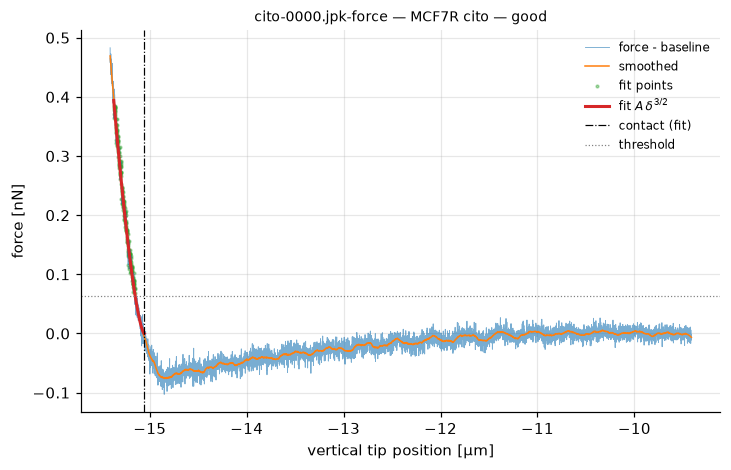

{'n_points': 6000,
 'fit_status': 'ok',
 'error': '',
 'baseline_slope_nN_per_um': -0.0234,
 'baseline_noise_pN': 7.945,
 'fmax_nN': 0.483,
 'snr': 60.7878,
 'contact_idx_initial': 5739,
 'contact_z_initial_um': -15.1526,
 'threshold_nN': 0.0636,
 'jump_score': 0.3014,
 'sat_fraction': 0.0002,
 'contact_z_fit_um': -15.0577,
 'contact_z_fit_err_um': 0.0021,
 'fit_force_low_nN': 0.0636,
 'fit_force_high_nN': 0.3864,
 'n_fit_points': 216,
 'A_nN_per_um_3over2': 2.2357,
 'A_err_nN_per_um_3over2': 0.0301,
 'max_indentation_um': 0.3142,
 'contact_shift_rel': -0.0158,
 'exponent_hat': 1.4708,
 'fit_rmse_nN': 0.0117,
 'fit_rmse_rel': 0.0242,
 'fit_r2': 0.9844,
 'fit_quality_flag': 'good'}

In [2]:
m = manifest.iloc[0]
z, f = T.read_curve(T.CODE_DIR / m["csv_path"])
res = T.fit_curve(z, f, return_arrays=True)
fig, ax = plt.subplots(figsize=(7.5, 4.5))
T.plot_fit(ax, res, f"{m['file_name']} — {T.short_group(m['group'])} — {res['fit_quality_flag']}")
ax.legend(fontsize=8); plt.show()
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in res.items() if k != "_arrays"}

## 2. Nominal fit on all curves

Nominal configuration (`afm_tools.NOMINAL`): baseline on the first 30% of the curve, threshold $\max(8\sigma,\,5\%\,F_{max})$ over 20 consecutive points, fit window between 8% and 80% of $F_{max}$.

In [3]:
fit = T.fit_manifest(manifest, T.NOMINAL)

# curve-by-curve diagnostic plots (regenerable cache, not tracked)
for _, m in manifest.iterrows():
    z, f = T.read_curve(T.CODE_DIR / m["csv_path"])
    r = T.fit_curve(z, f, return_arrays=True)
    if r["fit_status"] != "ok": continue
    fig, ax = plt.subplots(figsize=(7, 4))
    T.plot_fit(ax, r, f"{m['group']} / {m['file_name']}  A={r['A_nN_per_um_3over2']:.3f}  R²={r['fit_r2']:.3f}")
    fig.savefig(PLOTS_DIR / f"{m['group']}__{m['file_name'].replace('.jpk-force','')}.png"); plt.close(fig)

print(fit["fit_status"].value_counts().to_dict())
print(pd.crosstab(fit["group"].map(T.short_group), fit["fit_quality_flag"]))

{'ok': 257}
fit_quality_flag  good
group                 
MCF7R cito          55
MCF7R nucleo        60
T47DR cito          59
T47DR nucleo        83


## 3. Additional features (instrumental QC and retract)

We merge the preliminary-QC features (notebook 01) and the retract adhesion into the fit result: they are used by notebook 05.

In [4]:
qc_cols = ["file_name", "group", "z_monotonicity_fraction", "force_jump_score", "force_corr_max_nN",
           "signal_to_noise", "baseline_noise_pN", "qc_score_preliminary_global", "qc_flag_preliminary_any"]
extra = manifest[qc_cols].rename(columns={"baseline_noise_pN": "baseline_noise_pN_nb01",
                                          "signal_to_noise": "signal_to_noise_nb01"})
ret = pd.DataFrame([T.retract_features(p) for p in manifest["csv_path"]])
ret["file_name"] = manifest["file_name"].values; ret["group"] = manifest["group"].values

fit_full = (fit.merge(extra, on=["file_name", "group"]).merge(ret, on=["file_name", "group"]))
fit_full = fit_full.drop(columns=["error"])
fit_full.to_csv(T.FIT_TABLE_PATH, index=False)
print(fit_full.shape, "->", T.FIT_TABLE_PATH.relative_to(T.CODE_DIR))
fit_full[["A_nN_per_um_3over2", "logA", "fit_r2", "n_fit_points", "snr", "max_indentation_um",
          "adhesion_nN"]].describe().round(3)

(257, 40) -> results/fit_results_segment0.csv


,A_nN_per_um_3over2,logA,fit_r2,n_fit_points,snr,max_indentation_um,adhesion_nN
count,257.000,257.000,257.000,257.000,257.000,257.000,257.000
mean,0.894,-0.300,0.983,546.210,70.131,0.774,0.071
std,0.646,0.589,0.010,219.134,12.689,0.296,0.032
min,0.235,-1.448,0.924,146.000,31.873,0.191,0.010
25%,0.466,-0.764,0.980,370.000,62.348,0.538,0.051
50%,0.695,-0.364,0.986,506.000,70.358,0.734,0.067
75%,1.148,0.138,0.989,722.000,79.032,1.008,0.084
max,5.114,1.632,0.995,1191.000,100.465,1.647,0.211


## 4. Contact point quality

The contact point is the most delicate parameter: we compare the initial (threshold) estimate with the fitted one, and look at the distribution of the maximum indentation and of $R^2$.

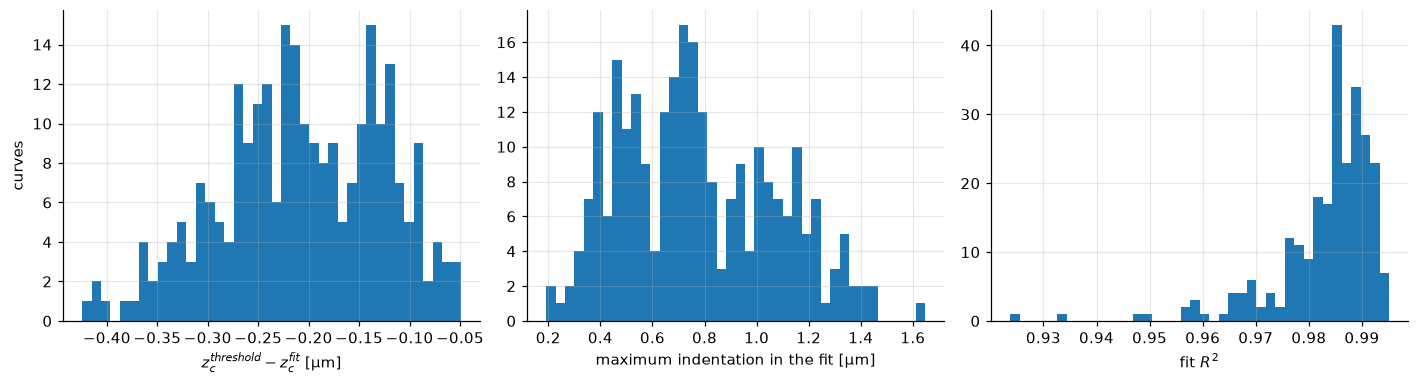

contact shift: median -0.208 µm, 95% within 0.343 µm


In [5]:
d = fit_full["contact_z_initial_um"] - fit_full["contact_z_fit_um"]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
ax[0].hist(d, bins=40); ax[0].set_xlabel(r"$z_c^{threshold} - z_c^{fit}$ [µm]"); ax[0].set_ylabel("curves")
ax[1].hist(fit_full["max_indentation_um"], bins=40); ax[1].set_xlabel("maximum indentation in the fit [µm]")
ax[2].hist(fit_full["fit_r2"], bins=40); ax[2].set_xlabel(r"fit $R^2$")
plt.tight_layout(); plt.show()
print("contact shift: median %.3f µm, 95%% within %.3f µm" % (d.median(), d.abs().quantile(.95)))

## 5. Distribution of $A$ per group

A first look (the real statistical analysis is in notebooks 03–05). $A$ is positive and skewed: we work on $\log A$.

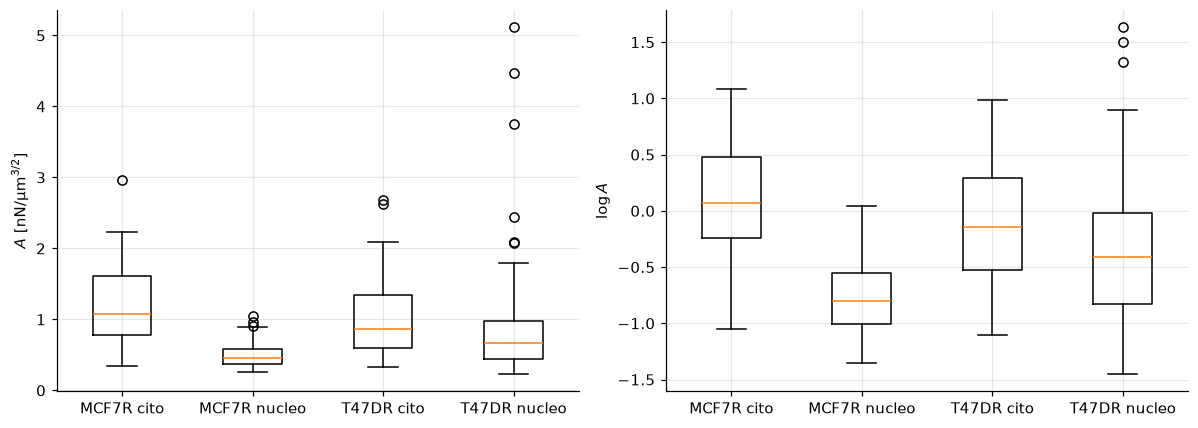

,count,mean,std,median
group,,,,
MCF7R cito,55,0.057,0.477,0.072
MCF7R nucleo,60,-0.757,0.327,-0.798
T47DR cito,59,-0.101,0.508,-0.146
T47DR nucleo,83,-0.348,0.637,-0.414


In [6]:
order = [g for g in T.GROUP_ORDER if g in set(fit_full["group"])]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for k, col, lab in [(0, "A_nN_per_um_3over2", r"$A$ [nN/µm$^{3/2}$]"), (1, "logA", r"$\log A$")]:
    ax[k].boxplot([fit_full.loc[fit_full.group == g, col] for g in order],
                  tick_labels=[T.short_group(g) for g in order]); ax[k].set_ylabel(lab)
plt.tight_layout(); plt.show()
fit_full.groupby(fit_full.group.map(T.short_group)).logA.agg(["count", "mean", "std", "median"]).round(3)

## 6. Preprocessing variants (for the systematics)

Each variant changes **one** parameter only (baseline, threshold, lower or upper edge of the fit window). Notebook 03 uses this table to quantify how much the conclusions depend on the preprocessing choices.

In [7]:
cols = ["file_name", "group", "A_nN_per_um_3over2", "logA", "fit_r2", "fit_quality_flag"]
rows = []
for name, cfg in T.VARIANTS.items():
    v = fit_full[cols].copy() if name == "nominal" else T.fit_manifest(manifest, cfg)[cols]
    v.insert(0, "variant", name); rows.append(v)
variants = pd.concat(rows, ignore_index=True)
variants.to_csv(T.RESULTS_DIR / "fit_variants.csv", index=False)
(variants.assign(g=variants.group.map(T.short_group))
         .pivot_table(index="variant", columns="g", values="logA", aggfunc="median").round(3))

g,MCF7R cito,MCF7R nucleo,T47DR cito,T47DR nucleo
variant,,,,
baseline_20%,0.068,-0.794,-0.135,-0.427
baseline_40%,0.056,-0.816,-0.160,-0.445
nominal,0.072,-0.798,-0.146,-0.414
threshold_12sigma,0.074,-0.791,-0.128,-0.439
threshold_6sigma,0.090,-0.800,-0.152,-0.410
window_high_60%,0.074,-0.871,-0.107,-0.433
window_high_95%,0.068,-0.762,-0.108,-0.425
window_low_15%,0.059,-0.798,-0.140,-0.419
window_low_4%,0.072,-0.798,-0.146,-0.414


## Output produced and next step

```text
results/
├── fit_results_segment0.csv   one row per curve: contact, A, errors, R², flag, QC and retract features
└── fit_variants.csv           logA per curve and per preprocessing variant (long format)
afm_output/fit_plots/          one PNG per curve (cache, not tracked)
```

No curve has been excluded. Next notebooks, which read only `results/`:

- `03_frequentist_analysis.ipynb` — group comparison with likelihood, bootstrap, toy MC, systematics;
- `04_bayesian_analysis.ipynb` — Bayesian model of $\log A$;
- `05_ml_curve_analysis.ipynb` — anomaly detection and classification.